# 3. Vault strike selection, graduation, seats
BLUEPRINT §5, §9 and §10 (2026-10-23).

In [1]:
import csv
from pathlib import Path
OUT = Path("../out")

def load(name):
    """rows of out/<name>.csv as dicts (numbers stay strings; use f())"""
    with open(OUT / f"{name}.csv") as fh:
        return list(csv.DictReader(fh))

def f(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return x

def show(rows, cols=None, limit=40, where=None):
    """print rows as an aligned table"""
    if where:
        rows = [r for r in rows if where(r)]
    rows = rows[:limit]
    if not rows:
        print("(no rows)"); return
    cols = cols or list(rows[0].keys())
    def fmt(v):
        try:
            x = float(v)
            return f"{x:,.4g}" if abs(x) < 1e6 else f"{x:,.0f}"
        except (TypeError, ValueError):
            return str(v)
    cells = [[fmt(r.get(c, "")) for c in cols] for r in rows]
    w = [max(len(c), *(len(row[i]) for row in cells)) for i, c in enumerate(cols)]
    print(" | ".join(c.ljust(w[i]) for i, c in enumerate(cols)))
    print("-+-".join("-" * x for x in w))
    for row in cells:
        print(" | ".join(v.rjust(w[i]) for i, v in enumerate(row)))

def svg(name):
    """display a pre-rendered chart from out/plots"""
    p = OUT / "plots" / name
    try:
        from IPython.display import SVG, display
        display(SVG(filename=str(p)))
    except Exception:
        print(f"[chart: {p}]")

## Which strike does each vault pick?
Honest market: five strikes over three expiries, 3400 is the main tier (400 k USDC per expiry). The attacker opens K = 6800 (or 1000) and wash-trades. v0.7 is hijacked by a 20 USDC wash; v0.8 ignores it, but out-volume-ing the main tier flips both vaults for ~0.03 % of the wash notional per expiry. develop's guard (protective limit and candidates from the previous VWAP) closes that path; see notebook 5.

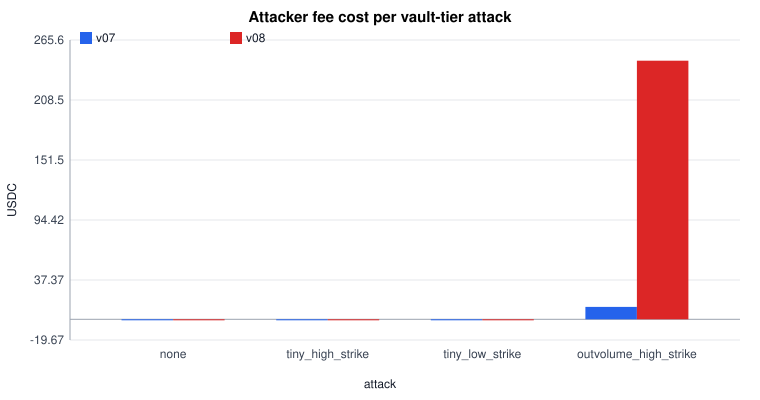

In [2]:
svg("vault_tier_cost.svg")  # attacker cost per attack

In [3]:
show(load("vault_tier"))

rules | attack                | attacker_wash_usdc | attacker_fee_cost_usdc | low_vault_strike | high_vault_strike | honest_main_strike | low_vault_hijacked | high_vault_hijacked
------+-----------------------+--------------------+------------------------+------------------+-------------------+--------------------+--------------------+--------------------
  v07 |                  none |                  0 |                      0 |            3,200 |             3,600 |              3,400 |              false |               false
  v07 |      tiny_high_strike |                 20 |               0.000294 |            3,200 |             6,800 |              3,400 |              false |                true
  v07 |       tiny_low_strike |                 20 |               0.002002 |            1,000 |             3,600 |              3,400 |               true |               false
  v07 | outvolume_high_strike |              8e+05 |                  11.77 |            3,200 |         

## Graduation: volume (v0.7) vs fees paid (v0.8)

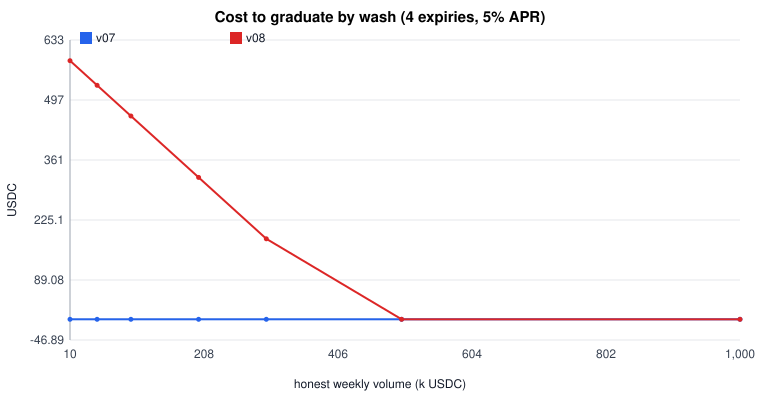

In [4]:
svg("graduation_cost.svg")  # cost to graduate by wash

In [5]:
show(load("graduation"), where=lambda r: r["honest_apr"] == "0.05")

rules | honest_weekly_volume_usdc | honest_apr | honest_metric | threshold | graduates_honestly | wash_volume_needed_usdc | attacker_cost_per_expiry_usdc | attacker_cost_4_expiries_usdc
------+---------------------------+------------+---------------+-----------+--------------------+-------------------------+-------------------------------+------------------------------
  v07 |                     1e+04 |       0.05 |         1e+04 |     5e+05 |              false |                 4.9e+05 |                             0 |                             0
  v07 |                     5e+04 |       0.05 |         5e+04 |     5e+05 |              false |                 4.5e+05 |                             0 |                             0
  v07 |                     1e+05 |       0.05 |         1e+05 |     5e+05 |              false |                   4e+05 |                             0 |                             0
  v07 |                     2e+05 |       0.05 |         2e+05 |     5

## Seat economics (BLUEPRINT §9) and bootstrap market maker
Seat income = 70 % / 35 % of the market's treasury revenue; Harberger tax 15 %/yr; the obligation ties up ~half a week of 10 %-of-batch bids. A seat is viable when someone would pay ≥ 1,000 USDC for it at a 12 % required return.

In [6]:
show(load("seats"), ["weekly_volume_usdc","apr","graduated","seat_income_yearly_usdc","obligation_capital_usdc","breakeven_seat_price_usdc","seat_price_at_12pct_required_return_usdc","viable"], where=lambda r: r["apr"] == "0.05")

weekly_volume_usdc | apr  | graduated | seat_income_yearly_usdc | obligation_capital_usdc | breakeven_seat_price_usdc | seat_price_at_12pct_required_return_usdc | viable
-------------------+------+-----------+-------------------------+-------------------------+---------------------------+------------------------------------------+-------
             1e+05 | 0.05 |     false |                   1,267 |                   5,000 |                     8,443 |                                    4,691 |   true
             1e+05 | 0.05 |      true |                   633.3 |                   5,000 |                     4,222 |                                    2,345 |   true
             3e+05 | 0.05 |     false |                   3,800 |                 1.5e+04 |                 2.533e+04 |                                1.407e+04 |   true
             3e+05 | 0.05 |      true |                   1,900 |                 1.5e+04 |                 1.267e+04 |                               

In [7]:
show(load("bootstrap_mm"))

weekly_volume_usdc | batches_per_week | mm_bid_per_batch_usdc | mm_capital_usdc | spread_pct | expected_weekly_pnl_usdc | weeks_until_seat_or_exit | budget_usdc
-------------------+------------------+-----------------------+-----------------+------------+--------------------------+--------------------------+------------
             1e+05 |              336 |                 148.8 |         2.5e+04 |        0.5 |                      100 |                       26 |    2.75e+04
             3e+05 |              336 |                 446.4 |         7.5e+04 |        0.5 |                      300 |                       26 |    8.25e+04
         1,000,000 |              336 |                 1,488 |         2.5e+05 |        0.5 |                    1,000 |                        8 |    2.75e+05
